# Shrimp Intelligence Ecuador — Análisis exploratorio (EDA)

**Pregunta gancho:** Ecuador es potencia mundial en camarón, pero ¿qué tan arriesgada es su dependencia
de pocos mercados, y qué pasaría con los ingresos si el principal comprador baja su precio?

Este notebook muestra los hallazgos principales con **un gráfico por idea** y **la conclusión escrita
debajo**. Los datos salen de la capa **gold** del proyecto, a través de las mismas consultas de
`sql/queries/` (una sola fuente de verdad). Cada gráfico se guarda también en `docs/img/`.

**Cómo leer las cifras**
- El **total** de cada año es el del **Banco Central del Ecuador** (valor FOB oficial).
- El **detalle por país** viene de **UN Comtrade**: lo que declara Ecuador (FOB) y, en los años sin ese
  dato (2022–2023 y 2025), lo que declaran los países compradores (*espejo*, valor CIF).
- **"Sin reporte por país"** (gris) es la parte del total oficial que ninguna fuente detalla. En 2025 es
  la mitad del total porque **China no reportó** sus importaciones.
- La finca *Acuícola Del Golfo* de la última sección es **SIMULADA**.


In [12]:
# Configuración: ruta del proyecto, librerías y estilo común
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

from src.eda_style import (COLORS, MARKET_COLORS, apply_style, draw_flows, es_number,
                           load_query, percent, query, save_fig, source_note, thousands, titled)

apply_style()
MONTHS_ES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

## 1. ¿Cuánto exporta Ecuador y a quién?

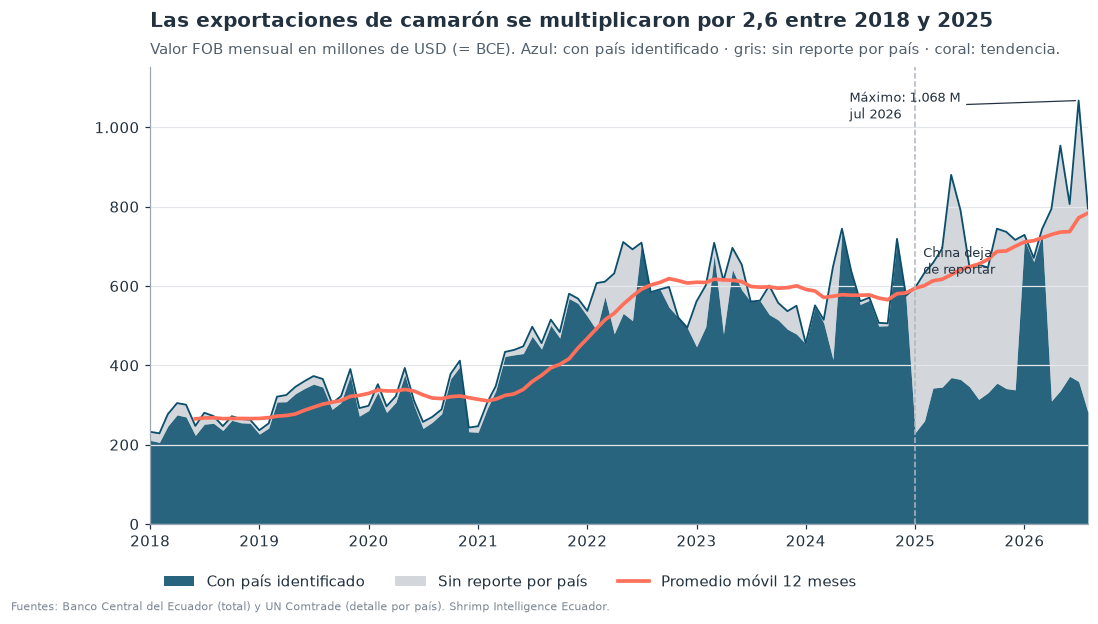

In [13]:
# Gráfico 1 — El "río" de las exportaciones: valor mensual (= BCE) y la parte sin país
monthly = query("""
    SELECT d.month_start_date                                               AS mes_fecha,
           SUM(f.value_usd)                                                 AS total_usd,
           SUM(CASE WHEN f.country_key = 9999 THEN f.value_usd ELSE 0 END)  AS sin_reporte_usd
    FROM gold.fact_exports AS f
    JOIN gold.dim_date AS d ON d.date_key = f.date_key
    WHERE f.is_preferred = 1
    GROUP BY d.month_start_date
    ORDER BY mes_fecha
""")
monthly["mes_fecha"] = pd.to_datetime(monthly["mes_fecha"])
monthly[["total_usd", "sin_reporte_usd"]] = monthly[["total_usd", "sin_reporte_usd"]].astype(float) / 1e6
monthly["con_pais"] = (monthly["total_usd"] - monthly["sin_reporte_usd"].clip(lower=0))
monthly["tendencia"] = monthly["total_usd"].rolling(12, min_periods=6).mean()

x, total, con_pais = monthly["mes_fecha"], monthly["total_usd"], monthly["con_pais"]
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.fill_between(x, 0, con_pais, color=COLORS["ocean"], alpha=0.88, linewidth=0,
                label="Con país identificado")
ax.fill_between(x, con_pais, total, color=COLORS["grey"], alpha=0.55, linewidth=0,
                label="Sin reporte por país")
ax.plot(x, total, color=COLORS["ocean"], linewidth=1.2)
ax.plot(x, monthly["tendencia"], color=COLORS["coral"], linewidth=2.4,
        label="Promedio móvil 12 meses")

peak = monthly.loc[total.idxmax()]
ax.annotate(f"Máximo: {es_number(peak['total_usd'])} M\n{MONTHS_ES[peak['mes_fecha'].month - 1]} "
            f"{peak['mes_fecha'].year}", xy=(peak["mes_fecha"], peak["total_usd"]),
            xytext=(-150, -4), textcoords="offset points", fontsize=8.5, va="center",
            arrowprops=dict(arrowstyle="-", color=COLORS["text"], lw=0.8))
gap_start = monthly.loc[monthly["sin_reporte_usd"] > 0.4 * total, "mes_fecha"].min()
if pd.notna(gap_start):
    ax.axvline(gap_start, color=COLORS["grey"], linestyle="--", linewidth=1)
    ax.text(gap_start, total.max() * 0.62, "  China deja\n  de reportar", fontsize=8.5,
            color=COLORS["text"], va="center", ha="left")

yearly = monthly.groupby(monthly["mes_fecha"].dt.year)["total_usd"].agg(["sum", "count"])
full = yearly[yearly["count"] == 12]
growth = full["sum"].iloc[-1] / full["sum"].iloc[0]
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0, total.max() * 1.08)
ax.set_xlim(x.min(), x.max())
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=3)
titled(ax, f"Las exportaciones de camarón se multiplicaron por {es_number(growth, 1)} "
           f"entre {full.index[0]} y {full.index[-1]}",
       "Valor FOB mensual en millones de USD (= BCE). Azul: con país identificado · gris: sin reporte "
       "por país · coral: tendencia.")
source_note(fig)
save_fig(fig, "01_rio_exportaciones")
plt.show()

**Conclusión.** El valor exportado pasó de 3.190 M USD (2018) a **8.401 M USD (2025)**: la tendencia
(línea coral) sube casi sin pausa, salvo la meseta de 2023–2024. Desde 2025 el río "se nubla": **más de la
mitad del valor no tiene país identificado** porque China no reportó sus importaciones. El total sigue
siendo completo (BCE); lo que falta es el detalle por destino.

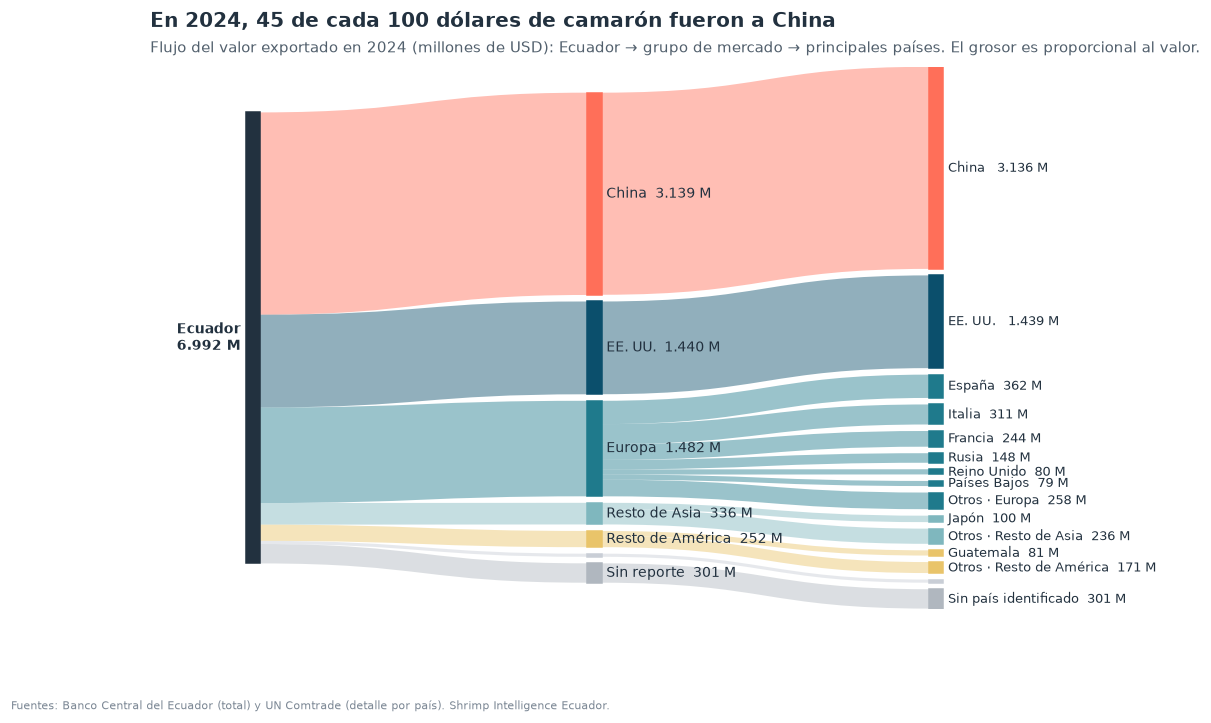

In [14]:
# Gráfico 2 — ¿A dónde va el camarón? Diagrama de flujos del último año completo y comparable
q01 = load_query("q01")
q02 = load_query("q02")
comparable_years = q01[(q01["meses"] == 12) & (q01["cobertura_pct"] >= 80)]["anio"]
year = int(comparable_years.max())
row = q01.set_index("anio").loc[year]
total = row["total_musd"]

groups = [("China", "china_pct"), ("EE. UU.", "eeuu_pct"), ("Europa", "europa_pct"),
          ("Resto de Asia", "resto_asia_pct"), ("Resto de América", "resto_america_pct"),
          ("Otros", "otros_pct"), ("Sin reporte", "sin_reporte_pct")]
group_value = {g: total * (row[c] if pd.notna(row[c]) else 0) / 100 for g, c in groups}

top = q02[(q02["anio"] == year) & (q02["puesto"] <= 10)]
SHORT = {"Estados Unidos": "EE. UU.", "Países Bajos": "Países Bajos", "Reino Unido": "Reino Unido"}
left = [("Ecuador", total, COLORS["text"])]
middle = [(g, v, MARKET_COLORS[g]) for g, v in group_value.items() if v > 0]
right, links = [], []
for g, v, color in middle:
    links.append(("Ecuador", g, v, color))
    countries = top[top["grupo"] == g]
    used = 0.0
    for _, c in countries.iterrows():
        name = SHORT.get(c["pais"], c["pais"])
        if name == g:                       # China → China, EE. UU. → EE. UU.: nodo propio
            name = f"{name} "
        right.append((name, c["usd_musd"], color))
        links.append((g, name, c["usd_musd"], color))
        used += c["usd_musd"]
    rest = v - used
    if rest > total * 0.004:
        label = "Sin país identificado" if g == "Sin reporte" else f"Otros · {g}"
        right.append((label, rest, color))
        links.append((g, label, rest, color))

fig, ax = plt.subplots(figsize=(11, 6.4))
draw_flows(ax, [left, middle, right], links, label_min=total * 0.01,
           value_fmt=lambda v: f"{es_number(v)} M")
china = group_value["China"] / total * 100
titled(ax, f"En {year}, {china:.0f} de cada 100 dólares de camarón fueron a China",
       f"Flujo del valor exportado en {year} (millones de USD): Ecuador → grupo de mercado → principales "
       "países. El grosor es proporcional al valor.")
source_note(fig)
save_fig(fig, "02_flujo_destinos")
plt.show()

**Conclusión.** En el último año completo con detalle por país (2024), **casi la mitad del valor (45 %)
fue a un solo país: China**. Le siguen EE. UU. (21 %) y Europa (21 %), donde el valor se reparte entre
muchos países (España, Italia, Francia…). Es la imagen del riesgo de concentración: **un solo comprador
mueve casi la mitad de los ingresos del sector**.

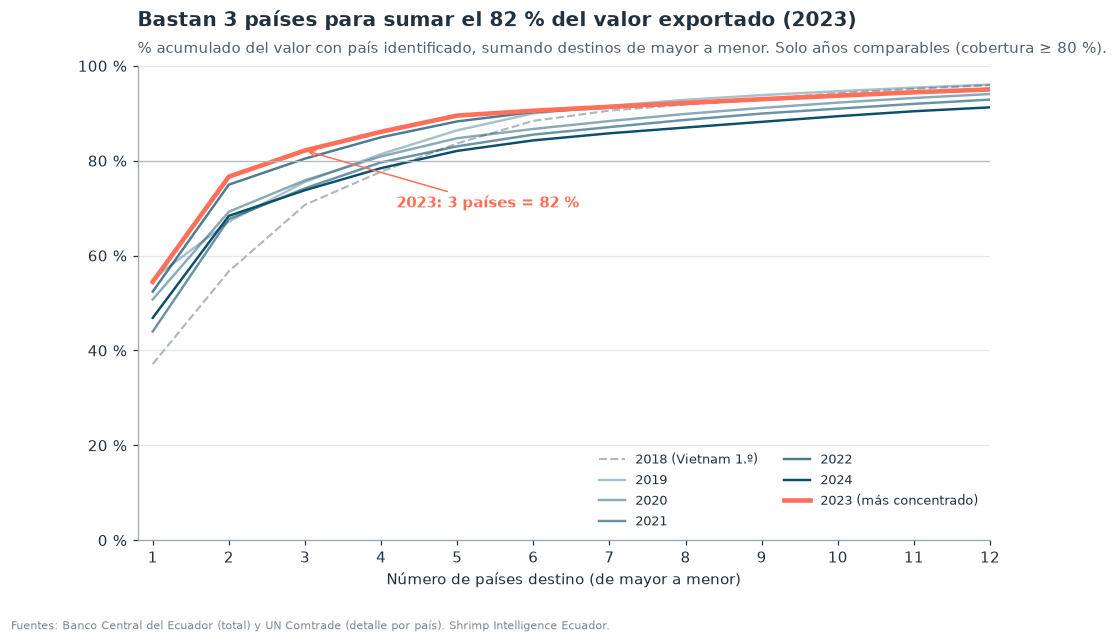

In [15]:
# Gráfico 3 — Curva de concentración: ¿cuántos países hacen falta para sumar el 80 %?
countries = query("""
    SELECT d.calendar_year AS anio, c.country_name_es AS pais, SUM(f.value_usd) AS pais_usd
    FROM gold.fact_exports AS f
    JOIN gold.dim_date    AS d ON d.date_key    = f.date_key
    JOIN gold.dim_country AS c ON c.country_key = f.country_key
    WHERE f.is_preferred = 1 AND f.country_key NOT IN (0, 9999)
    GROUP BY d.calendar_year, c.country_name_es
""")
q03 = load_query("q03")
comparable = q03.loc[q03["comparabilidad"].eq("Comparable"), "anio"].tolist()
N = 12

fig, ax = plt.subplots(figsize=(10, 5.6))
summary = {}
for yr in comparable:                                   # 1.º se calculan todas las curvas
    d = countries[countries["anio"] == yr].sort_values("pais_usd", ascending=False)
    summary[yr] = (d["pais_usd"].astype(float).cumsum()
                   / d["pais_usd"].astype(float).sum() * 100).to_numpy()[:N]
best = max((y for y in comparable if y != 2018), key=lambda y: summary[y][2])
for yr in [y for y in comparable if y != best]:        # 2.º se dibujan (la más concentrada al final)
    share = summary[yr]
    k = np.arange(1, len(share) + 1)
    if yr == 2018:
        ax.plot(k, share, color=COLORS["grey"], linestyle="--", linewidth=1.4, label="2018 (Vietnam 1.º)")
    else:
        shade = 0.35 + 0.65 * (yr - 2019) / max(1, max(comparable) - 2019)
        ax.plot(k, share, color=COLORS["ocean"], alpha=shade, linewidth=1.6, label=str(yr))
ax.plot(np.arange(1, N + 1), summary[best], color=COLORS["coral"], linewidth=3,
        label=f"{best} (más concentrado)")
ax.axhline(80, color=COLORS["grey"], linewidth=0.8)
ax.annotate(f"{best}: 3 países = {summary[best][2]:.0f} %", xy=(3, summary[best][2]),
            xytext=(4.2, summary[best][2] - 12), fontsize=9.5, color=COLORS["coral"],
            fontweight="bold", arrowprops=dict(arrowstyle="->", color=COLORS["coral"]))
ax.set_xticks(range(1, N + 1))
ax.set_xlabel("Número de países destino (de mayor a menor)")
ax.set_ylim(0, 100)
ax.set_xlim(0.8, N)
ax.yaxis.set_major_formatter(percent)
ax.legend(loc="lower right", ncol=2, fontsize=8.5)
titled(ax, f"Bastan 3 países para sumar el {summary[best][2]:.0f} % del valor exportado ({best})",
       "% acumulado del valor con país identificado, sumando destinos de mayor a menor. Solo años "
       "comparables (cobertura ≥ 80 %).")
source_note(fig)
save_fig(fig, "03_curva_concentracion")
plt.show()

**Conclusión.** Las curvas suben muy rápido: **con solo 3 países se supera el 74 % del valor en todos los
años comparables desde 2019**, y en 2023 se llega al 82 %. El índice HHI lo confirma: entre 2.599 y 3.521,
siempre en la zona de "muy concentrado" (> 2.500). 2018 (línea gris) era menos concentrado, con Vietnam como
primer destino. 2025–2026 no se muestran: sin China, la curva sería engañosamente plana.

## 2. ¿Se vende más por menos? Precio, volumen y estacionalidad

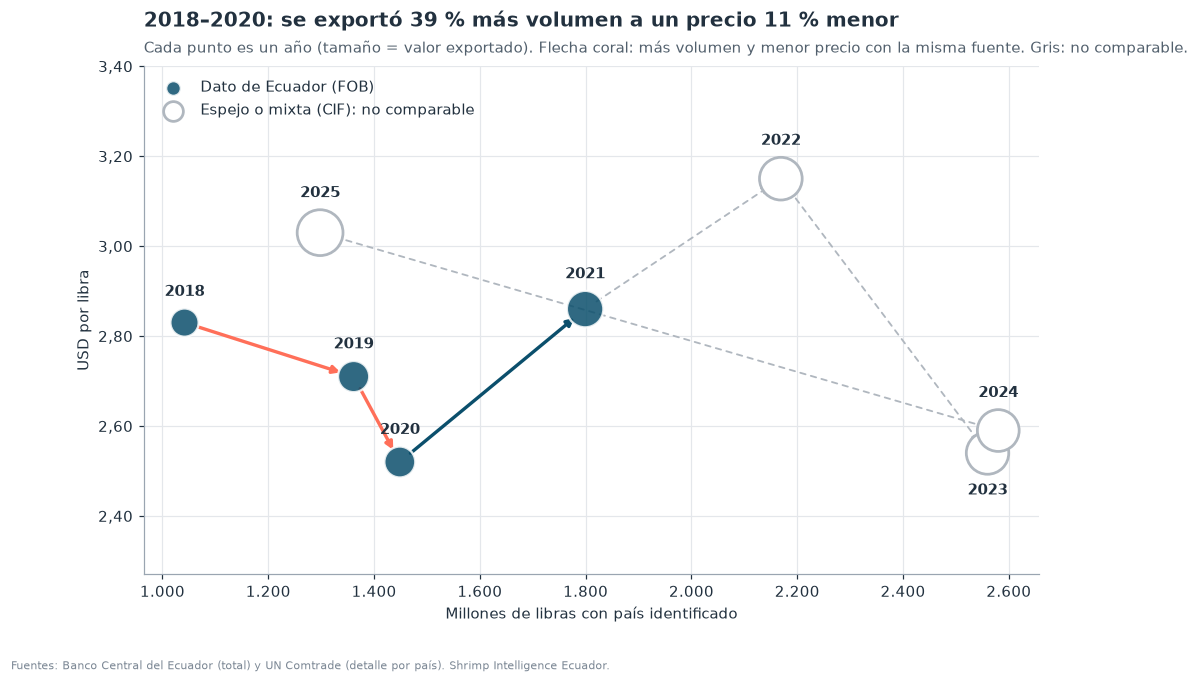

In [16]:
# Gráfico 4 — El camino del sector: volumen vs precio, año a año (q04)
q04 = load_query("q04")
q04 = q04[q04["meses"] == 12].reset_index(drop=True)          # solo años completos
fob = q04["fuente_precio"].eq("UN_COMTRADE")                   # misma fuente (FOB): comparables

fig, ax = plt.subplots(figsize=(10.5, 6))
xs, ys = q04["lb_identificadas_m"].to_numpy(float), q04["usd_lb"].to_numpy(float)
for i in range(len(q04) - 1):                                  # flechas entre años consecutivos
    both_fob = fob.iloc[i] and fob.iloc[i + 1]
    color = COLORS["coral"] if both_fob and ys[i + 1] < ys[i] else (
        COLORS["ocean"] if both_fob else COLORS["grey"])
    ax.annotate("", xy=(xs[i + 1], ys[i + 1]), xytext=(xs[i], ys[i]),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2.2 if both_fob else 1.2,
                                linestyle="-" if both_fob else (0, (3, 3)), shrinkA=9, shrinkB=9))
sizes = q04["valor_musd"].to_numpy(float) / q04["valor_musd"].max() * 900
ax.scatter(xs[fob], ys[fob], s=sizes[fob], color=COLORS["ocean"], alpha=0.85, zorder=3,
           edgecolor="white", linewidth=1.5, label="Dato de Ecuador (FOB)")
ax.scatter(xs[~fob], ys[~fob], s=sizes[~fob], facecolor="white", edgecolor=COLORS["grey"],
           linewidth=1.8, zorder=3, label="Espejo o mixta (CIF): no comparable")
for x, y, yr, s in zip(xs, ys, q04["anio"], sizes):
    below = any(abs(x - x2) < 120 and 0 < y2 - y < 0.15 for x2, y2 in zip(xs, ys))  # vecino encima
    off = (np.sqrt(s) / 2 + 6) * (-1 if below else 1)
    ax.annotate(str(yr), (x, y), xytext=(0, off), textcoords="offset points", ha="center",
                va="top" if below else "bottom", fontsize=9.5, fontweight="bold", zorder=4)

a, b = q04[q04["anio"] == 2018].iloc[0], q04[q04["anio"] == 2020].iloc[0]
dv = (b["lb_identificadas_m"] / a["lb_identificadas_m"] - 1) * 100
dp = (b["usd_lb"] / a["usd_lb"] - 1) * 100
ax.set_xlabel("Millones de libras con país identificado")
ax.set_ylabel("USD por libra")
ax.xaxis.set_major_formatter(thousands)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: es_number(v, 2)))
ax.grid(True, axis="both")
ax.set_ylim(ys.min() - 0.25, ys.max() + 0.25)
ax.legend(loc="upper left", markerscale=0.45)
titled(ax, f"2018–2020: se exportó {dv:.0f} % más volumen a un precio {abs(dp):.0f} % menor",
       "Cada punto es un año (tamaño = valor exportado). Flecha coral: más volumen y menor precio "
       "con la misma fuente. Gris: no comparable.")
source_note(fig)
save_fig(fig, "04_volumen_vs_precio")
plt.show()

**Conclusión.** Entre 2018 y 2020 el sector recorrió el camino clásico de la **presión de precios**: casi
**40 % más libras** vendidas a un precio **11 % menor** (de 2,83 a 2,52 USD/lb, FOB). 2021 rompe la tendencia
(precio +13,5 %). Desde 2022 los puntos son grises: el precio viene del espejo (CIF, incluye flete) y no se
puede comparar directamente; aun así, en 2023 el valor cayó con más volumen, una señal de presión que se
repite. *Control cruzado:* el BCE reporta 3.074 M lb en 2025 → 2,73 USD/lb FOB, coherente con los 3,03 CIF
del espejo (≈ +11 % por flete y seguro).

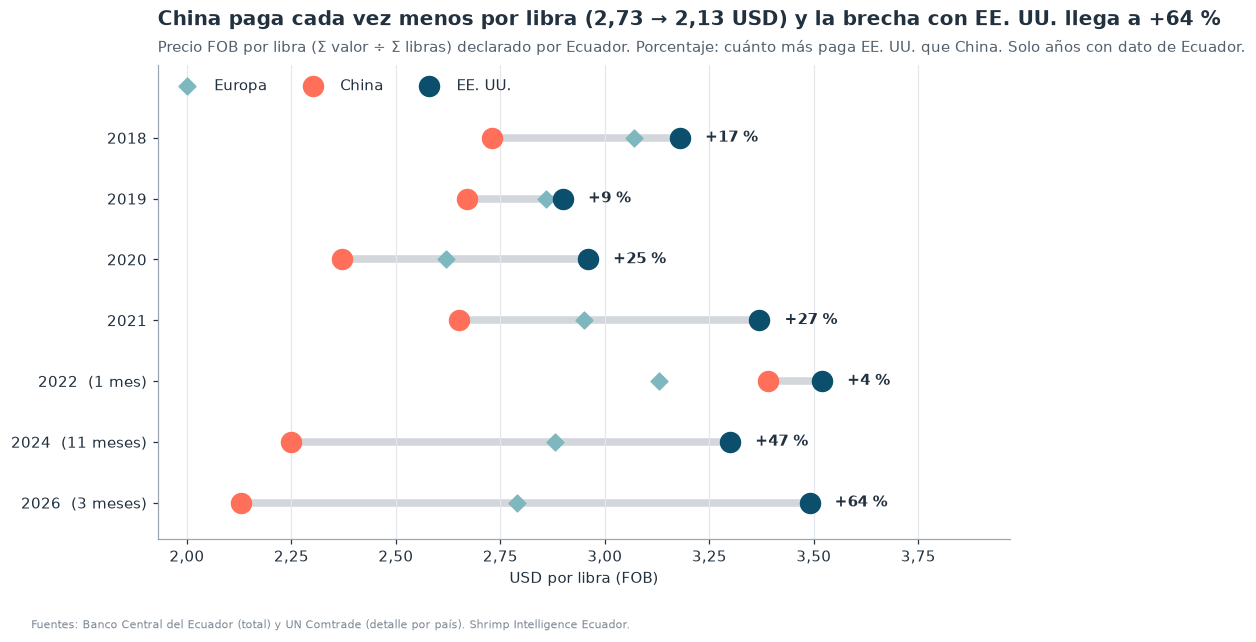

In [17]:
# Gráfico 5 — Dumbbell: China vs EE. UU., precio por libra (q05, solo FOB)
q05 = load_query("q05").sort_values("anio", ascending=False).reset_index(drop=True)
y = np.arange(len(q05))

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.hlines(y, q05["china_usd_lb"], q05["eeuu_usd_lb"], color=COLORS["grey"], linewidth=5,
          alpha=0.55, zorder=1)
ax.scatter(q05["europa_usd_lb"], y, s=60, marker="D", color=COLORS["ocean_light"], zorder=2,
           label="Europa")
ax.scatter(q05["china_usd_lb"], y, s=170, color=COLORS["coral"], zorder=3, label="China")
ax.scatter(q05["eeuu_usd_lb"], y, s=170, color=COLORS["ocean"], zorder=3, label="EE. UU.")
for i, r in q05.iterrows():
    ax.text(r["eeuu_usd_lb"] + 0.06, i, f"+{r['prima_eeuu_vs_china_pct']:.0f} %",
            va="center", fontsize=9.5, fontweight="bold", color=COLORS["text"])
labels = [f"{a}" + (f"  ({m} mes{'es' if m > 1 else ''})" if m < 12 else "")
          for a, m in zip(q05["anio"], q05["meses"])]
ax.set_yticks(y, labels)
ax.grid(True, axis="x")
ax.grid(False, axis="y")
ax.set_xlabel("USD por libra (FOB)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: es_number(v, 2)))
ax.set_xlim(q05[["china_usd_lb", "europa_usd_lb"]].min().min() - 0.2, q05["eeuu_usd_lb"].max() + 0.45)
ax.set_ylim(-0.6, len(q05) + 0.2)                                # espacio para la leyenda
ax.legend(loc="upper left", ncol=3)

old, new = q05.iloc[-1], q05.iloc[0]
titled(ax, f"China paga cada vez menos por libra ({es_number(old['china_usd_lb'], 2)} → "
           f"{es_number(new['china_usd_lb'], 2)} USD) y la brecha con EE. UU. llega a "
           f"+{new['prima_eeuu_vs_china_pct']:.0f} %",
       "Precio FOB por libra (Σ valor ÷ Σ libras) declarado por Ecuador. Porcentaje: cuánto más paga "
       "EE. UU. que China. Solo años con dato de Ecuador.")
source_note(fig)
save_fig(fig, "05_precio_china_vs_eeuu")
plt.show()

**Conclusión.** Este es probablemente **el hallazgo más fuerte del proyecto**: el mayor comprador es el
que **paga la libra más barata, y cada vez menos** (2,65 USD en 2021 → 2,25 en 2024 → 2,13 en 2026). EE. UU.
se mantiene entre 3,30 y 3,49, y la brecha pasa de **+9 % (2019) a +47 % (2024) y +64 % (ene–mar 2026)**.
Depender de China no solo concentra el riesgo: **concentra el volumen en el mercado de menor precio**.
*Hipótesis por verificar:* la mezcla de producto (China compra más camarón entero; EE. UU., cola y
pelado, de mayor valor por libra). Las partidas HS disponibles no lo separan. 2022 (1 mes) y 2026 (3 meses)
son referencias parciales.

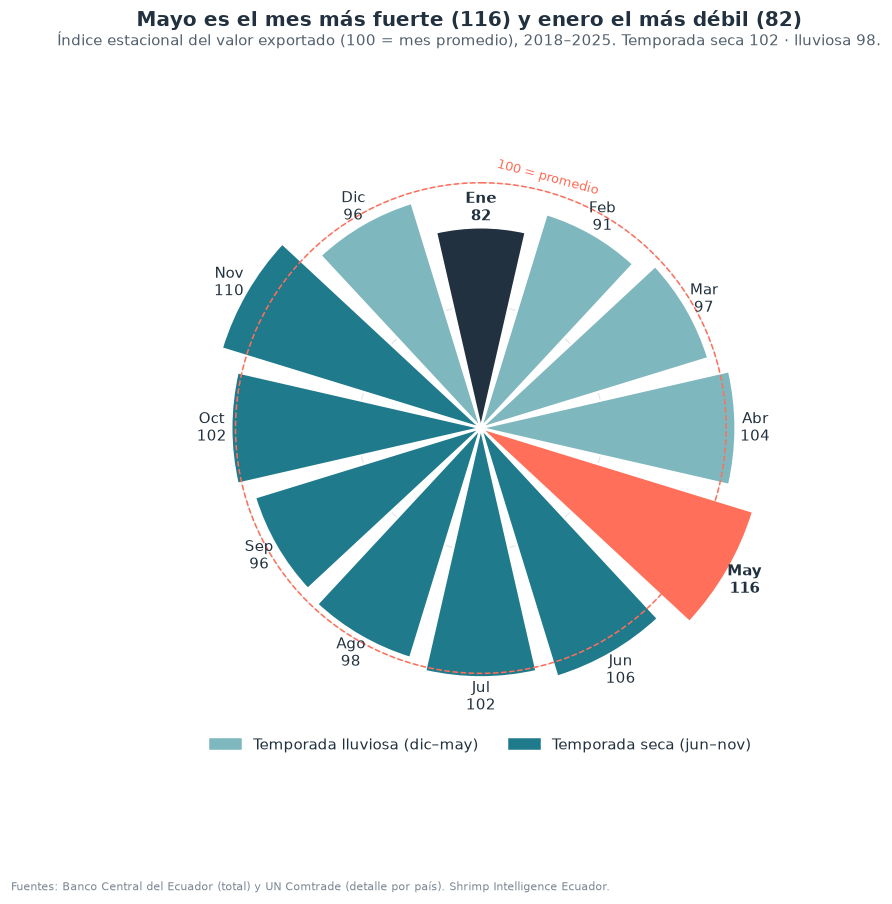

In [18]:
# Gráfico 6 — Radial: el año del camarón, índice estacional por mes (q06)
q06 = load_query("q06").sort_values("mes")
theta = np.linspace(0, 2 * np.pi, 12, endpoint=False)
width = 2 * np.pi / 12 * 0.86
values = q06["indice"].to_numpy(float)
top, low = values.argmax(), values.argmin()
colors = [COLORS["ocean_light"] if t == "lluviosa" else COLORS["ocean_mid"] for t in q06["temporada"]]
colors[top], colors[low] = COLORS["coral"], COLORS["text"]

fig = plt.figure(figsize=(8.5, 8))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.bar(theta, values, width=width, color=colors, edgecolor="white", linewidth=1.5, zorder=2)
ax.plot(np.linspace(0, 2 * np.pi, 200), np.full(200, 100), color=COLORS["coral"],
        linestyle="--", linewidth=1, zorder=3)
ax.text(np.deg2rad(15), 103, "100 = promedio", fontsize=8.5, color=COLORS["coral"],
        ha="center", va="bottom", rotation=-15, rotation_mode="anchor")
for t, v, name in zip(theta, values, q06["mes_nombre"]):
    ax.text(t, v + 8, f"{name}\n{v:.0f}", ha="center", va="center", fontsize=9.5,
            fontweight="bold" if v in (values[top], values[low]) else "normal")
ax.set_ylim(0, values.max() + 22)
ax.set_xticks([])
ax.set_yticks([50, 100])
ax.set_yticklabels([])
ax.grid(color=COLORS["grey_light"])
ax.spines["polar"].set_visible(False)

seasons = q06.groupby("temporada")["indice_temporada"].first()
fig.suptitle(f"Mayo es el mes más fuerte ({values[top]:.0f}) y enero el más débil ({values[low]:.0f})"
             if top == 4 and low == 0 else
             f"{q06['mes_nombre'].iloc[top]} es el mes más fuerte ({values[top]:.0f}) y "
             f"{q06['mes_nombre'].iloc[low]} el más débil ({values[low]:.0f})", y=0.97, fontsize=13, fontweight="bold")
fig.text(0.5, 0.93, f"Índice estacional del valor exportado (100 = mes promedio), 2018–2025. "
                     f"Temporada seca {seasons['seca']:.0f} · lluviosa {seasons['lluviosa']:.0f}.",
         ha="center", fontsize=9.5, color="#52606D")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLORS["ocean_light"], label="Temporada lluviosa (dic–may)"),
                   Patch(color=COLORS["ocean_mid"], label="Temporada seca (jun–nov)")],
          loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=2)
source_note(fig)
save_fig(fig, "06_estacionalidad_radial")
plt.show()

**Conclusión.** El año del camarón tiene un **ciclo moderado**: **enero es el mes más débil (índice 82)**
y **mayo el más fuerte (116)**, seguido de noviembre (110,5). La temporada seca (jun–nov) queda apenas sobre la
lluviosa (102 vs 98). El patrón no es rígido: enero osciló entre 56 y 94 según el año. *Hipótesis:* el
enero débil podría relacionarse con el Año Nuevo chino (compras adelantadas en noviembre–diciembre).
Para planificar la cosecha, conviene **no concentrar la oferta en enero**.

## 3. ¿Qué tan confiables son las fuentes por país?

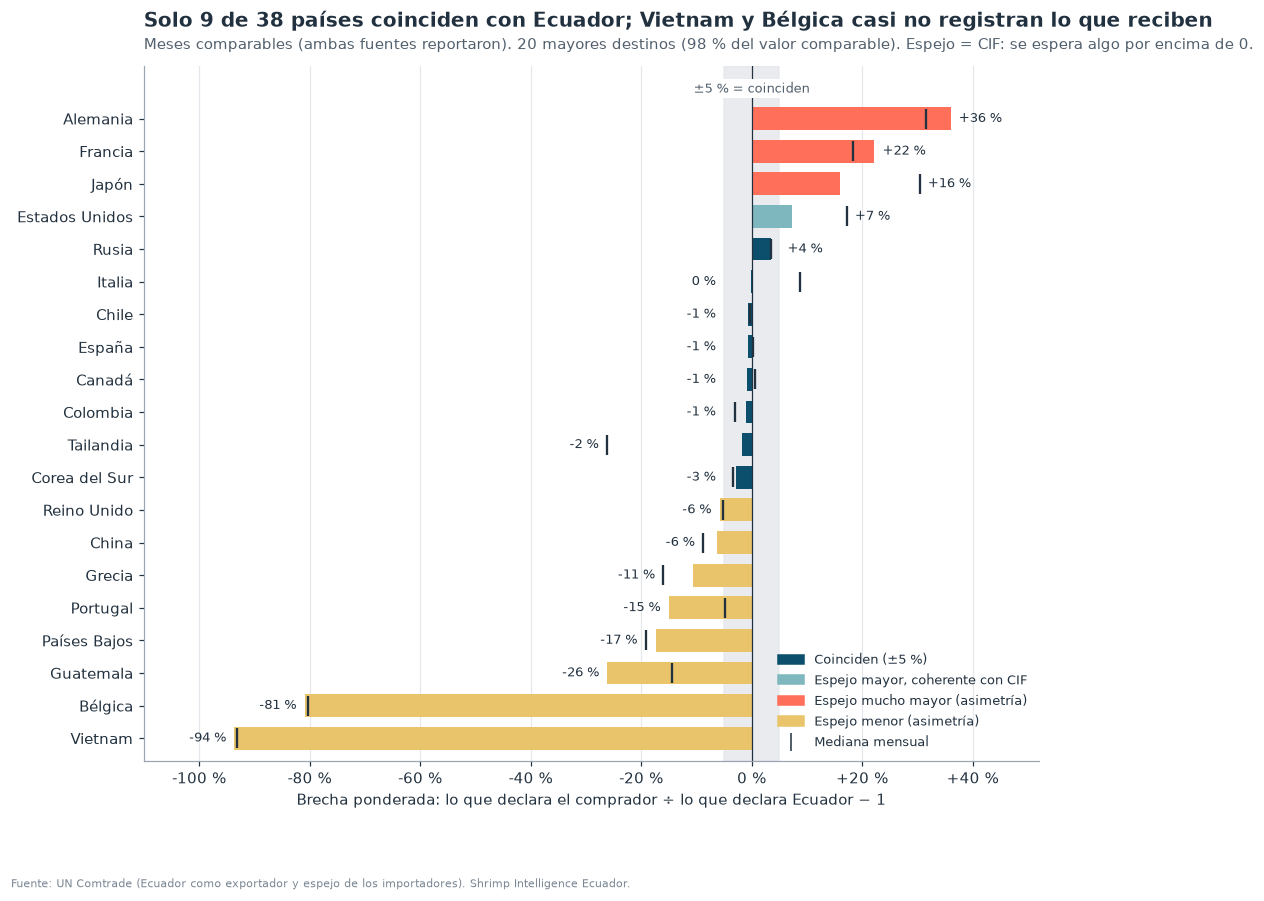

In [19]:
# Gráfico 7 — Barras divergentes: brecha espejo vs Ecuador por país (q12)
q12 = load_query("q12")
top = q12.nlargest(20, "ecuador_musd").sort_values("brecha_ponderada_pct").reset_index(drop=True)
coverage = top["ecuador_musd"].sum() / q12["ecuador_musd"].sum() * 100
CLASS_COLORS = {
    "Coinciden (±5 %)": COLORS["ocean"],
    "Espejo mayor, coherente con CIF": COLORS["ocean_light"],
    "Espejo mucho mayor (asimetría)": COLORS["coral"],
    "Espejo menor (asimetría)": COLORS["sand"],
}
y = np.arange(len(top))

fig, ax = plt.subplots(figsize=(10.5, 8.2))
ax.axvspan(-5, 5, color=COLORS["grey_light"], alpha=0.8, zorder=0)
ax.text(0, len(top) - 0.3, "±5 % = coinciden", ha="center", va="bottom", fontsize=8.5,
        color="#52606D", bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=4)
ax.barh(y, top["brecha_ponderada_pct"], color=top["clasificacion"].map(CLASS_COLORS),
        height=0.7, zorder=2)
ax.scatter(top["brecha_mediana_pct"], y, marker="|", s=160, color=COLORS["text"], zorder=3,
           label="Mediana mensual")
ax.axvline(0, color=COLORS["text"], linewidth=0.8, zorder=2)
def pct_label(v):
    text = f"{v:+.0f} %"
    return "0 %" if text in ("+0 %", "-0 %") else text

for i, r in top.iterrows():                         # etiqueta por fuera de la barra y de la mediana
    v, med = r["brecha_ponderada_pct"], r["brecha_mediana_pct"]
    if v >= 0:
        ax.text(max(v, med, 5) + 1.5, i, pct_label(v), va="center", ha="left", fontsize=8.5)
    else:
        ax.text(min(v, med, -5) - 1.5, i, pct_label(v), va="center", ha="right", fontsize=8.5)
ax.set_yticks(y, top["pais"])
ax.grid(True, axis="x")
ax.grid(False, axis="y")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: pct_label(v)))
ax.set_xlim(-110, 52)
ax.set_ylim(-0.7, len(top) + 0.6)
ax.set_xlabel("Brecha ponderada: lo que declara el comprador ÷ lo que declara Ecuador − 1")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLORS.values()]
handles.append(plt.Line2D([], [], marker="|", linestyle="none", markersize=12, color=COLORS["text"]))
ax.legend(handles, list(CLASS_COLORS) + ["Mediana mensual"], loc="lower right", fontsize=8.5)

n_ok = (q12["clasificacion"] == "Coinciden (±5 %)").sum()
titled(ax, f"Solo {n_ok} de {len(q12)} países coinciden con Ecuador; Vietnam y Bélgica casi no "
           f"registran lo que reciben",
       f"Meses comparables (ambas fuentes reportaron). 20 mayores destinos ({es_number(coverage)} % del "
       f"valor comparable). Espejo = CIF: se espera algo por encima de 0.")
source_note(fig, "Fuente: UN Comtrade (Ecuador como exportador y espejo de los importadores). "
                 "Shrimp Intelligence Ecuador.")
save_fig(fig, "07_brecha_por_pais")
plt.show()

**Conclusión.** Aunque el comprador declara CIF (flete y seguro incluidos, unos 5–10 % más), **solo 9 de 38
países coinciden** dentro de ±5 % (España, Italia, Corea, Chile, Canadá…). EE. UU. queda en +7 %, lo
esperable por el CIF. Las asimetrías grandes tienen dos lecturas (son **hipótesis**, ver ADR-006):
**Vietnam (−94 %) y Bélgica (−81 %)** registran muy poco de lo que Ecuador les despacha, probablemente porque
son **puertas de entrada** (a China y a la UE) o clasifican el producto en otra partida; **Francia (+22 %) y
Alemania (+36 %)** registran *más*, coherente con camarón ecuatoriano que llega reexpedido desde otro país
europeo. **China (−6 %)** casi coincide en lo ponderado, pero su mes típico se aleja más (−9 %). La raya
negra (mediana) muestra cuándo unos pocos meses grandes "maquillan" el total: en EE. UU. el mes típico es
+17 %. **Implicación:** el espejo sirve para estimar el año de un país grande, no para meses ni para
países de tránsito.

## 4. La finca: ¿qué mueve el margen? *(datos SIMULADOS)*

> La finca **Acuícola Del Golfo** (3 sedes, 45 piscinas, 2023–2026) es **SIMULADA**: el método es real y
> sirve con datos de una camaronera real; las cifras no describen a ninguna empresa.

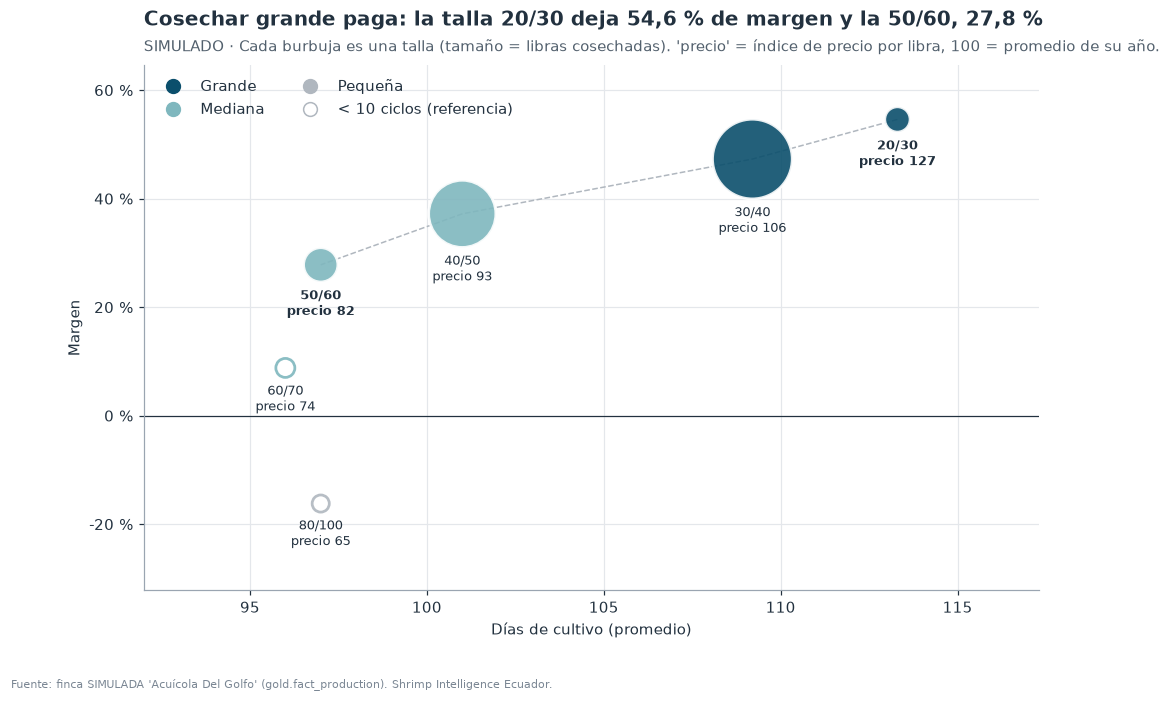

In [20]:
# Gráfico 8 — Burbujas: talla de cosecha, días de cultivo y margen (q09, SIMULADO)
q09 = load_query("q09").sort_values("orden")
GROUP_COLORS = {"Grande": COLORS["ocean"], "Mediana": COLORS["ocean_light"], "Pequeña": COLORS["grey"]}
solid = q09["ciclos"] >= 10                               # pocos ciclos = referencia, no conclusión

fig, ax = plt.subplots(figsize=(10.5, 6.2))
sizes = 120 + q09["millones_lb"] / q09["millones_lb"].max() * 2600
for is_solid in (True, False):
    part = q09[solid == is_solid]
    colors = part["grupo"].map(GROUP_COLORS)
    ax.scatter(part["dias_promedio"], part["margen_pct"], s=sizes[part.index],
               facecolor=colors if is_solid else "white", edgecolor=colors if not is_solid else "white",
               linewidth=1.8, alpha=0.9, zorder=3)
ax.plot(q09.loc[solid, "dias_promedio"], q09.loc[solid, "margen_pct"], color=COLORS["grey"],
        linewidth=1, linestyle="--", zorder=2)
for _, r in q09.iterrows():
    ax.annotate(f"{r['talla']}\nprecio {es_number(r['indice_precio'])}", (r["dias_promedio"], r["margen_pct"]),
                xytext=(0, -(np.sqrt(sizes[_]) / 2 + 4)), textcoords="offset points",
                ha="center", va="top", fontsize=8.5,
                fontweight="bold" if r["talla"] in ("20/30", "50/60") else "normal")
ax.axhline(0, color=COLORS["text"], linewidth=0.8)
ax.set_xlabel("Días de cultivo (promedio)")
ax.set_ylabel("Margen")
ax.yaxis.set_major_formatter(percent)
ax.set_xlim(q09["dias_promedio"].min() - 4, q09["dias_promedio"].max() + 4)
ax.set_ylim(q09["margen_pct"].min() - 16, q09["margen_pct"].max() + 10)
ax.grid(True, axis="both")
handles = [plt.Line2D([], [], marker="o", linestyle="none", markersize=9, color=c, label=g)
           for g, c in GROUP_COLORS.items()]
handles.append(plt.Line2D([], [], marker="o", linestyle="none", markersize=9, markerfacecolor="white",
                          markeredgecolor=COLORS["grey"], label="< 10 ciclos (referencia)"))
ax.legend(handles=handles, loc="upper left", ncol=2)

big, mid = q09[q09["talla"] == "20/30"].iloc[0], q09[q09["talla"] == "50/60"].iloc[0]
titled(ax, f"Cosechar grande paga: la talla 20/30 deja {es_number(big['margen_pct'], 1)} % de margen "
           f"y la 50/60, {es_number(mid['margen_pct'], 1)} %",
       "SIMULADO · Cada burbuja es una talla (tamaño = libras cosechadas). 'precio' = índice de precio "
       "por libra, 100 = promedio de su año.")
source_note(fig, "Fuente: finca SIMULADA 'Acuícola Del Golfo' (gold.fact_production). "
                 "Shrimp Intelligence Ecuador.")
save_fig(fig, "08_talla_margen")
plt.show()

**Conclusión (SIMULADO).** La talla es **el principal motor del margen**: cada escalón de talla sube el
precio por libra (índice 127 en 20/30 frente a 82,5 en 50/60) mucho más de lo que cuesta esperar. Pasar de
**40/50 a 30/40 cuesta unos 8 días más de cultivo y suma ~10 puntos de margen**. Las tallas 60/70 y 80/100
(burbujas vacías) tienen 4 y 1 ciclos: muestran el riesgo de una cosecha forzada (margen negativo), pero no
alcanzan para concluir. **Pregunta para una finca real:** ¿qué piscinas cosechan antes de tiempo y por qué?

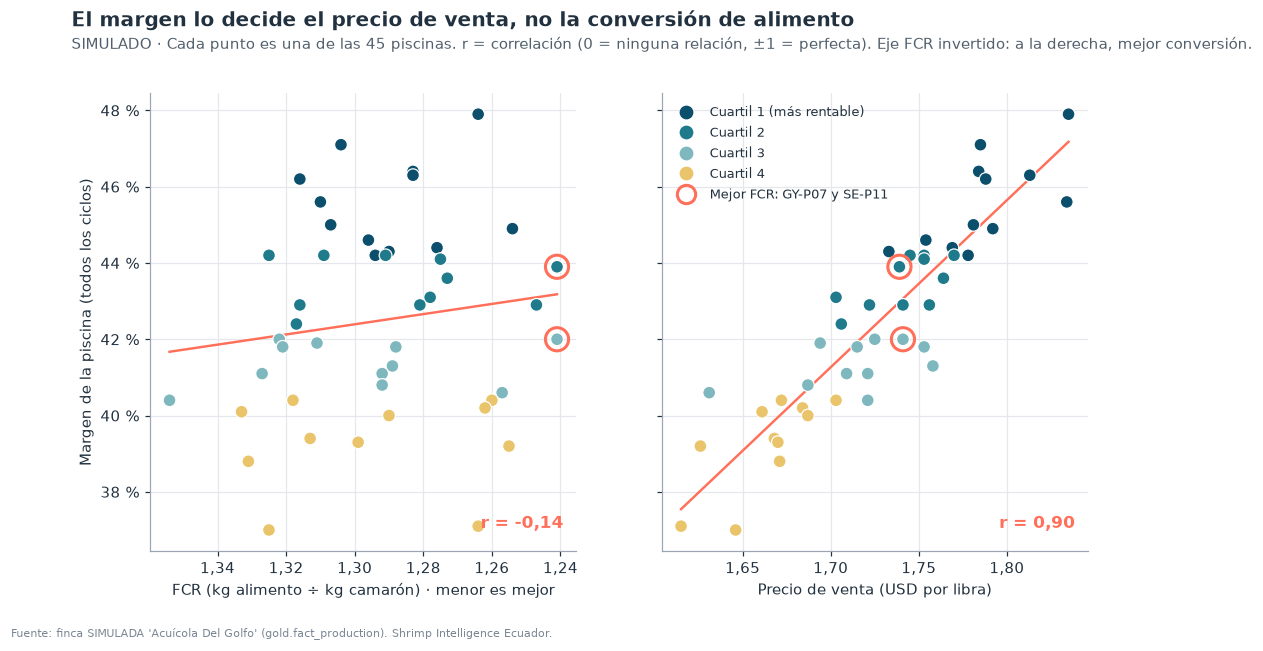

In [21]:
# Gráfico 9 — Dos paneles por piscina: margen vs FCR y margen vs precio por libra (q07 + q08, SIMULADO)
ponds = load_query("q07").merge(load_query("q08")[["finca", "piscina", "fcr", "puesto"]],
                                on=["finca", "piscina"], validate="one_to_one")
QUARTILE_COLORS = {1: COLORS["ocean"], 2: COLORS["ocean_mid"], 3: COLORS["ocean_light"], 4: COLORS["sand"]}
r_fcr = ponds["fcr"].corr(ponds["margen_pct"])
r_price = ponds["precio_lb"].corr(ponds["margen_pct"])

fig, axes = plt.subplots(1, 2, figsize=(11, 5.4), sharey=True)
for ax, col, label, r in ((axes[0], "fcr", "FCR (kg alimento ÷ kg camarón) · menor es mejor", r_fcr),
                          (axes[1], "precio_lb", "Precio de venta (USD por libra)", r_price)):
    ax.scatter(ponds[col], ponds["margen_pct"], c=ponds["cuartil"].map(QUARTILE_COLORS),
               s=70, edgecolor="white", linewidth=0.8, zorder=3)
    slope, intercept = np.polyfit(ponds[col], ponds["margen_pct"], 1)
    xs = np.linspace(ponds[col].min(), ponds[col].max(), 50)
    ax.plot(xs, slope * xs + intercept, color=COLORS["coral"], linewidth=1.6, zorder=2)
    ax.text(0.97, 0.05, f"r = {es_number(r, 2)}", transform=ax.transAxes, ha="right", fontsize=11,
            fontweight="bold", color=COLORS["coral"])
    ax.set_xlabel(label)
    ax.grid(True, axis="both")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: es_number(v, 2)))
axes[0].invert_xaxis()                                     # a la derecha = mejor FCR
axes[0].set_ylabel("Margen de la piscina (todos los ciclos)")
axes[0].yaxis.set_major_formatter(percent)

best = ponds[ponds["fcr"] == ponds["fcr"].min()].sort_values("margen_pct")   # puede haber empate
for ax in axes:                                            # anillo coral en las de mejor FCR
    ax.scatter(best["fcr"] if ax is axes[0] else best["precio_lb"], best["margen_pct"], s=230,
               facecolor="none", edgecolor=COLORS["coral"], linewidth=2, zorder=4)
handles = [plt.Line2D([], [], marker="o", linestyle="none", markersize=8, color=c,
                      label=f"Cuartil {q}" + (" (más rentable)" if q == 1 else ""))
           for q, c in QUARTILE_COLORS.items()]
handles.append(plt.Line2D([], [], marker="o", linestyle="none", markersize=12, markerfacecolor="none",
                          markeredgecolor=COLORS["coral"], markeredgewidth=2,
                          label="Mejor FCR: " + " y ".join(best["piscina"])))
axes[1].legend(handles=handles, loc="upper left", fontsize=8.5)

fig.suptitle("El margen lo decide el precio de venta, no la conversión de alimento", x=0.06,
             ha="left", fontsize=13, fontweight="bold", y=1.02)
fig.text(0.06, 0.955, f"SIMULADO · Cada punto es una de las {len(ponds)} piscinas. r = correlación "
                      "(0 = ninguna relación, ±1 = perfecta). Eje FCR invertido: a la derecha, mejor conversión.", fontsize=9.5, color="#52606D")
source_note(fig, "Fuente: finca SIMULADA 'Acuícola Del Golfo' (gold.fact_production). "
                 "Shrimp Intelligence Ecuador.")
save_fig(fig, "09_margen_fcr_precio")
plt.show()

**Conclusión (SIMULADO).** En las 45 piscinas el FCR va de 1,24 a 1,35 y **casi no explica el margen
(r ≈ −0,14)**: las dos piscinas con el mejor FCR (GY-P07 y SE-P11, empatadas) quedan en los cuartiles 3 y 2. En cambio, **el precio por
libra lo explica casi todo (r ≈ 0,90)**, y el precio depende de la talla cosechada (gráfico 8). Con costos
por libra parecidos entre piscinas (0,95–1,04 USD), **vender mejor pesa más que producir un poco más
barato**. *Límite:* en la simulación el FCR casi no varía; en una finca real la dispersión sería mayor y
conviene repetir este análisis.